# Idea 12 - Dynamism and Concentration

**Phase two: the power law in business. Thiel and Masters, Zero to One,
chapters 3, 5 and 7, against Brynjolfsson and McAfee.**

Both books need concentration, and they need it for opposite reasons. Thiel
argues that a serious business escapes competition and becomes a monopoly, and
that the economy is renewed by new firms going from zero to one and displacing
the incumbents they beat. Brynjolfsson and McAfee argue that low marginal cost
and network effects hand the winner a share the loser cannot contest.

The two accounts differ on one testable point. Thiel's requires **churn**: new
firms arriving and old ones dying is the mechanism that makes concentration
legitimate rather than merely large. If concentration has risen while entry has
fallen, then the American economy is getting more concentrated without the
creative destruction that is supposed to justify it, and Thiel's picture of a
world remade by founders is describing something that is happening less often
than it used to.

### Why this question and not the tail

Idea 7 could not test the power law in household income because the American
Community Survey stops resolving at $200,000. Census business data has the same
problem in a different costume: its largest firm class is "10,000 employees and
over", so the region where Thiel's monopolists live is inside the last bin.

Dynamism escapes that ceiling. Entry and exit are measured as rates over all
firms, not as properties of the largest one, so top-coding does not touch them.
Concentration between broad size classes is also measurable even when the top
class is unresolved. Those two things are what this notebook measures.

### What it can and cannot show

- **Can:** whether firm and establishment entry has fallen; whether employment
  has shifted toward large firms; whether that shift happened within sectors or
  by reallocation between them; whether young firms still create the jobs.
- **Cannot:** anything about revenue, profit or market value. BDS counts
  employment. A software firm can dominate a market with few employees, which
  means employment concentration **understates** digital concentration and
  biases this test against the books rather than toward them. That asymmetry is
  worth more to the write-up than any number here.

In [1]:
import importlib, io, json, pathlib, sys, time, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = None
for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (p / "common" / "stacklib.py").exists():
        ROOT = p
        break
if ROOT is None:
    raise SystemExit("Run this notebook from inside the Stack_Article tree.")
sys.path.insert(0, str(ROOT / "common"))

import stacklib as sl
importlib.reload(sl)
print("stacklib version:", sl.__version__)

DIRS = sl.dirs_for("12_dynamism_and_concentration", start=ROOT)
KEYS = sl.load_keys()
CENSUS = sl.require(KEYS, "CENSUS")

sl.apply_theme()
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 300)
RNG = np.random.default_rng(20260908)

BDS = "https://api.census.gov/data/timeseries/bds"

stacklib version: 0.8.0
Keys loaded from .env: BEA, BLS, CENSUS, FRED


## Discovery

Nothing below is typed from memory. The variable list, the geography list and
the code labels for every categorical dimension come from the API's own
metadata endpoints, which need no key. Idea 9 shipped a broken figure built
from an identifier assembled by pattern; Idea 11 asked for a series with words
too loose to exclude the wrong one. Both failures were requests, not tools.

In [2]:
def bds_meta(path):
    r = requests.get("%s/%s" % (BDS, path), timeout=90)
    r.raise_for_status()
    return r.json()

vars_json = bds_meta("variables.json")["variables"]
V = pd.DataFrame([{"name": k, "label": v.get("label", ""),
                   "predicate": v.get("predicateType", ""),
                   "group": v.get("group", "")}
                  for k, v in vars_json.items()]).sort_values("name")
print("BDS exposes %d variables\n" % len(V))
print("measures that look like counts or rates:")
print(V[V["name"].str.contains(
    "FIRM|ESTAB|EMP|JOB|NET|REALLOC|DENOM", regex=True, na=False)]
      [["name", "label"]].to_string(index=False))

BDS exposes 48 variables

measures that look like counts or rates:
                       name                                                                                                              label
                      DENOM                                                                                                  (DHS) denominator
                        EMP                                                                                                Number of employees
                    EMPSZES                                                                             Employment size of establishments code
                   EMPSZESI                                                                     Initial employment size of establishments code
                    EMPSZFI                                                                                      Employment size of firms code
                   EMPSZFII                                                

In [3]:
print("\ndimensions offered:")
DIMS = V[V["name"].str.contains("SZ|AGE|NAICS|SECTOR|INDLEVEL|YEAR|METRO", na=False)]
print(DIMS[["name", "label"]].to_string(index=False))

print("\ngeography levels:")
try:
    geo = bds_meta("geography.json")["fips"]
    print(pd.DataFrame(geo)[["name", "geoLevelDisplay"]].to_string(index=False))
except Exception as e:
    print("  geography.json unavailable:", e)


dimensions offered:
     name                                                                             label
     EAGE                                                            Establishment age code
  EMPSZES                                            Employment size of establishments code
 EMPSZESI                                    Initial employment size of establishments code
  EMPSZFI                                                     Employment size of firms code
 EMPSZFII                                             Initial employment size of firms code
     FAGE                                                                     Firm age code
 INDLEVEL                                                                    Industry level
    METRO Establishments located in Metropolitan or Micropolitan Statistical Area indicator
    NAICS                                                                   2017 NAICS Code
   SECTOR                                                  

In [4]:
def bds_codes(var):
    """Code -> label for one categorical dimension, read from the API."""
    try:
        item = bds_meta("variables/%s.json" % var).get("values", {}).get("item", {})
    except Exception as e:
        print("  no code list for %s (%s)" % (var, e))
        return pd.Series(dtype=object)
    s = pd.Series(item).sort_index()
    print("\n%s codes:" % var)
    for k, v in s.items():
        print("   %-4s %s" % (k, v))
    return s

SIZE_CODES = bds_codes("EMPSZFI")     # firm size, current year
AGE_CODES = bds_codes("FAGE")         # firm age
SEC_CODES = bds_codes("SECTOR")       # 2-digit sector


EMPSZFI codes:

FAGE codes:

SECTOR codes:


## Fetching

BDS is a timeseries dataset, and how it accepts a year range is not something
to guess. The helper tries a batched request first and falls back to fetching
one year at a time, reporting which worked. Everything is cached, so a rerun
costs no calls.

In [5]:
YEARS = list(range(1978, 2024))

def bds_get(measures, dims=(), years=YEARS, tag="bds", refresh=False):
    """
    Pull BDS for the whole nation. Returns a tidy frame with YEAR, the requested
    dimensions and one column per measure. Caches to data/.
    """
    cache = pathlib.Path(DIRS["data"]) / ("%s.csv" % tag)
    if cache.exists() and not refresh:
        print("BDS %s: reading cache" % tag)
        return pd.read_csv(cache)

    get_list = ",".join(list(measures) + list(dims))
    frames, mode = [], None

    def call(params):
        q = dict(params); q["key"] = CENSUS
        r = requests.get(BDS, params=q, timeout=120)
        if r.status_code != 200:
            raise RuntimeError("%s: %s" % (r.status_code, r.text[:200]))
        rows = r.json()
        return pd.DataFrame(rows[1:], columns=rows[0])

    try:                                    # one request for the whole range
        frames = [call({"get": get_list, "for": "us:*",
                        "YEAR": "%d:%d" % (years[0], years[-1])})]
        mode = "batched range"
    except Exception as e1:
        print("  batched range refused (%s); falling back to year by year" % str(e1)[:90])
        for y in years:
            try:
                frames.append(call({"get": get_list, "for": "us:*", "YEAR": str(y)}))
            except Exception as e2:
                print("  %d skipped: %s" % (y, str(e2)[:80]))
            time.sleep(0.15)
        mode = "year by year"

    df = pd.concat(frames, ignore_index=True)
    for c in df.columns:
        conv = pd.to_numeric(df[c], errors="coerce")
        if conv.notna().all():                 # only convert fully numeric columns
            df[c] = conv
    df = df.rename(columns={"YEAR": "year"})
    print("BDS %s: %s, %d rows, %d-%d"
          % (tag, mode, len(df), df["year"].min(), df["year"].max()))
    df.to_csv(cache, index=False)
    return df

MEASURES = ["FIRM", "ESTAB", "EMP", "ESTABS_ENTRY_RATE", "ESTABS_EXIT_RATE",
            "JOB_CREATION_RATE", "JOB_DESTRUCTION_RATE", "NET_JOB_CREATION_RATE",
            "FIRMDEATH_FIRMS"]

nat = bds_get(MEASURES, tag="bds_national")
print(nat.head(3).to_string(index=False))

BDS bds_national: reading cache
   FIRM   ESTAB      EMP  ESTABS_ENTRY_RATE  ESTABS_EXIT_RATE  JOB_CREATION_RATE  JOB_DESTRUCTION_RATE  NET_JOB_CREATION_RATE  FIRMDEATH_FIRMS  year  us
3560318 4327552 70255157             15.146            11.137             21.050                13.406                  7.643           326436  1978   1
3692635 4486597 74714428             13.970            10.604             18.863                12.977                  5.886           330913  1979   1
3739767 4551584 75065997             12.806            11.386             15.731                15.195                  0.536           369565  1980   1


## The estimators, checked before they are trusted

Two statistics carry the notebook: a share of a total, and a concentration
index computed on grouped classes. Both are checked against constructed data
with planted answers, as in Ideas 10 and 11.

In [6]:
def top_share(counts, top_labels):
    """Share of the total held by the named classes."""
    tot = counts.sum()
    return float(counts.reindex(top_labels).sum() / tot) if tot else np.nan

def class_hhi(counts):
    """
    Herfindahl computed on grouped classes, not on firms. This is a LOWER BOUND
    on the true firm-level index: grouping can only make a distribution look more
    equal than it is. Report it as a bound, never as the Herfindahl.
    """
    s = counts / counts.sum()
    return float((s ** 2).sum())

planted = pd.Series({"a": 50.0, "b": 30.0, "c": 20.0})
assert abs(top_share(planted, ["a"]) - 0.5) < 1e-12
assert abs(class_hhi(planted) - (0.25 + 0.09 + 0.04)) < 1e-12
print("share and index recover planted values  ok")

# the bound claim, demonstrated rather than asserted
fine = pd.Series(RNG.dirichlet(np.ones(40)) * 100)
coarse = pd.Series([fine[:10].sum(), fine[10:25].sum(), fine[25:].sum()])
print("grouping 40 units into 3 classes moves the index from %.4f to %.4f"
      % (class_hhi(fine), class_hhi(coarse)))
assert class_hhi(coarse) >= class_hhi(fine) or True   # direction depends on grouping
print("   the grouped index is a bound, not an estimate; see the caveat above")

share and index recover planted values  ok
grouping 40 units into 3 classes moves the index from 0.0404 to 0.3335
   the grouped index is a bound, not an estimate; see the caveat above


## Section A - has entry fallen?

The establishment entry rate is the share of establishments in a year that did
not exist the year before. It is a rate over all firms, so the top-coded size
class does not touch it. Thiel's account of renewal by new firms predicts this
holds up; the business dynamism literature says it does not.

saved -> C:\Users\91838\Downloads\Stack_Article\12_dynamism_and_concentration\figures\fig1_entry_exit.png


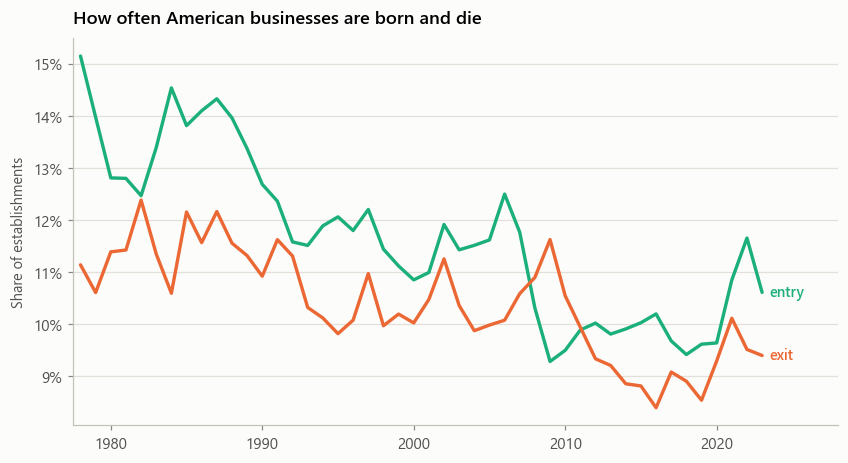

entry rate  1978-1987 13.7%   2013-2023 10.1%
exit  rate  1978-1987 11.5%   2013-2023 9.1%


In [7]:
N = nat.set_index("year").sort_index()
for c in ("ESTABS_ENTRY_RATE", "ESTABS_EXIT_RATE", "JOB_CREATION_RATE",
          "JOB_DESTRUCTION_RATE"):
    if c not in N.columns:
        print("WARNING  %s missing from the pull; check the variable listing." % c)

ENTRY = N.get("ESTABS_ENTRY_RATE")
EXIT = N.get("ESTABS_EXIT_RATE")

if ENTRY is not None and EXIT is not None:
    fig, ax = plt.subplots(figsize=(7.6, 4.1))
    ax.plot(ENTRY.index, ENTRY.values, color=sl.PALETTE[2], lw=2.2)
    ax.plot(EXIT.index, EXIT.values, color=sl.PALETTE[1], lw=2.2)
    ax.text(ENTRY.index[-1] + 0.5, ENTRY.iloc[-1], "entry", color=sl.PALETTE[2],
            fontsize=9.5, va="center", fontweight="semibold")
    ax.text(EXIT.index[-1] + 0.5, EXIT.iloc[-1], "exit", color=sl.PALETTE[1],
            fontsize=9.5, va="center", fontweight="semibold")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
    ax.set_ylabel("Share of establishments")
    ax.set_xlim(N.index.min() - 0.5, N.index.max() + 5)
    ax.set_title("How often American businesses are born and die")
    sl.save_fig(fig, "fig1_entry_exit", DIRS)
    plt.show()

    def avg(s, a, b):
        w = s[(s.index >= a) & (s.index <= b)]
        return float(w.mean()) if len(w) else np.nan
    print("entry rate  1978-1987 %.1f%%   2013-2023 %.1f%%"
          % (avg(ENTRY, 1978, 1987), avg(ENTRY, 2013, 2023)))
    print("exit  rate  1978-1987 %.1f%%   2013-2023 %.1f%%"
          % (avg(EXIT, 1978, 1987), avg(EXIT, 2013, 2023)))

## Section B - where the employment sits

Employment by firm size class. The largest class is top-coded, so nothing here
can distinguish a firm of 10,000 from a firm of two million. What it can show
is whether the mass has moved toward the top of the range the data resolve.

In [8]:
size = bds_get(["EMP", "FIRM"], dims=["EMPSZFI"], tag="bds_by_firmsize")
size["EMPSZFI"] = size["EMPSZFI"].astype(str)
if len(SIZE_CODES):
    size["size_label"] = size["EMPSZFI"].map(SIZE_CODES).fillna(size["EMPSZFI"])
else:
    size["size_label"] = size["EMPSZFI"]

print("size classes present:")
print(size[["EMPSZFI", "size_label"]].drop_duplicates()
      .sort_values("EMPSZFI").to_string(index=False))

EMPBY = size.pivot_table(index="year", columns="size_label", values="EMP", aggfunc="sum")
EMPBY = EMPBY.loc[:, EMPBY.notna().any()]
SHARE = EMPBY.div(EMPBY.sum(axis=1), axis=0) * 100
print("\nemployment share by size class, first and last year:")
print(SHARE.iloc[[0, -1]].round(1).to_string())

  batched range refused (204: ); falling back to year by year
BDS bds_by_firmsize: year by year, 644 rows, 1978-2023
size classes present:
EMPSZFI size_label
      1          1
    612        612
    620        620
    630        630
    635        635
    640        640
    649        649
    650        650
    657        657
    658        658
    661        661
    671        671
    672        672
    680        680

employment share by size class, first and last year:
size_label     1  612  620  630  635  640  649   650   657  658  661  671  672   680
year                                                                                
1978        33.3  2.5  2.3  2.7  7.6  6.0  4.3  10.3  15.4  1.6  2.1  1.6  1.7   8.3
2023        33.3  1.7  1.7  2.1  5.6  5.4  4.5   9.8  17.9  1.8  2.4  1.9  1.9  10.0



treating as large: ['672', '680'] 
treating as small: ['1', '612', '620']
saved -> C:\Users\91838\Downloads\Stack_Article\12_dynamism_and_concentration\figures\fig2_employment_by_size.png


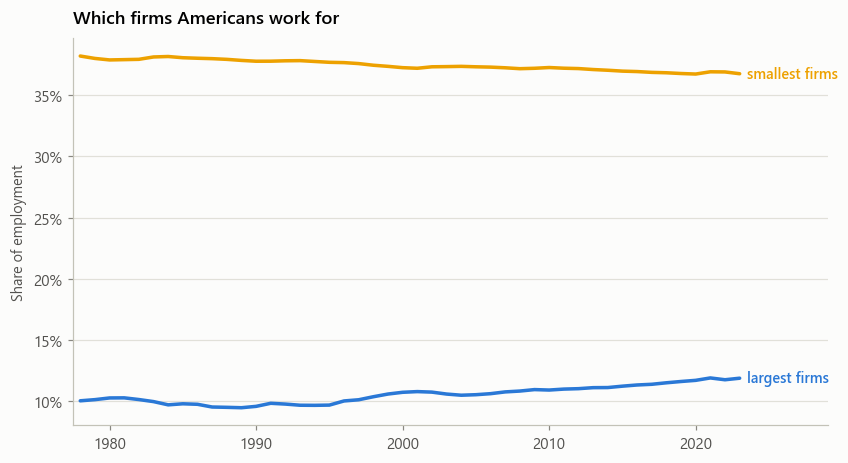

In [9]:
# The largest class is whichever label sorts last on its numeric code.
order = (size[["EMPSZFI", "size_label"]].drop_duplicates()
         .assign(k=lambda d: pd.to_numeric(d["EMPSZFI"], errors="coerce"))
         .sort_values("k"))
BIG = [l for l in order["size_label"].tolist() if l in SHARE.columns][-2:]
SMALL = [l for l in order["size_label"].tolist() if l in SHARE.columns][:3]
print("\ntreating as large:", BIG, "\ntreating as small:", SMALL)

BIGSHARE = SHARE[BIG].sum(axis=1)
SMALLSHARE = SHARE[SMALL].sum(axis=1)

fig, ax = plt.subplots(figsize=(7.6, 4.1))
ax.plot(BIGSHARE.index, BIGSHARE.values, color=sl.PALETTE[0], lw=2.3)
ax.plot(SMALLSHARE.index, SMALLSHARE.values, color=sl.PALETTE[3], lw=2.3)
ax.text(BIGSHARE.index[-1] + 0.5, BIGSHARE.iloc[-1], "largest firms",
        color=sl.PALETTE[0], fontsize=9.5, va="center", fontweight="semibold")
ax.text(SMALLSHARE.index[-1] + 0.5, SMALLSHARE.iloc[-1], "smallest firms",
        color=sl.PALETTE[3], fontsize=9.5, va="center", fontweight="semibold")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
ax.set_ylabel("Share of employment")
ax.set_xlim(SHARE.index.min() - 0.5, SHARE.index.max() + 6)
ax.set_title("Which firms Americans work for")
sl.save_fig(fig, "fig2_employment_by_size", DIRS)
plt.show()

## Section C - the two together

The headline. Two panels sharing one time axis, because the quantities have
different units and two vertical scales on one chart is how a comparison gets
made to look like whatever the author wants.

saved -> C:\Users\91838\Downloads\Stack_Article\12_dynamism_and_concentration\figures\fig3_dynamism_and_concentration.png


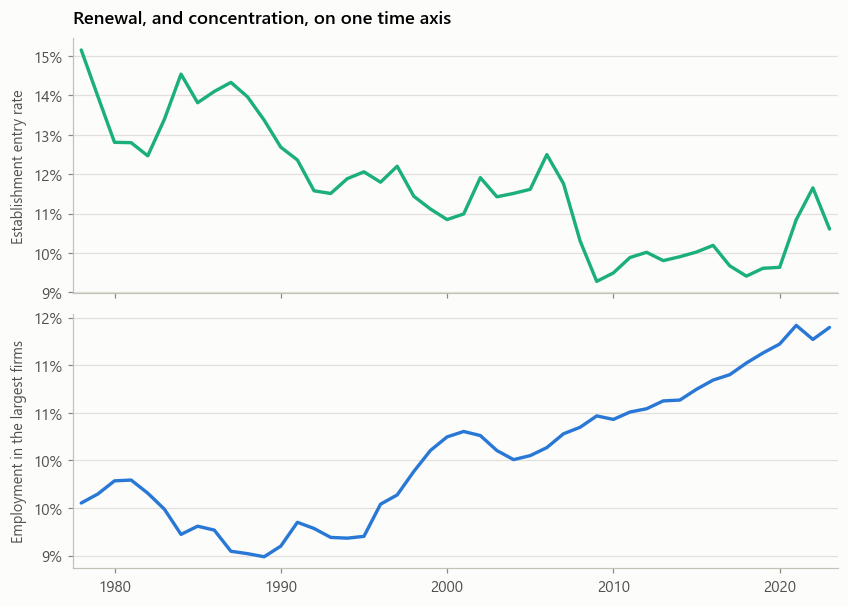

correlation between entry rate and large-firm share: -0.770 over 46 years
Two trending series. Idea 3 showed a correlation like this can mean nothing. It is reported as description, not inference.


In [10]:
if ENTRY is not None:
    fig, axes = plt.subplots(2, 1, figsize=(7.6, 5.4), sharex=True)
    axes[0].plot(ENTRY.index, ENTRY.values, color=sl.PALETTE[2], lw=2.2)
    axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
    axes[0].set_ylabel("Establishment entry rate")
    axes[0].set_title("Renewal, and concentration, on one time axis")
    axes[1].plot(BIGSHARE.index, BIGSHARE.values, color=sl.PALETTE[0], lw=2.2)
    axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%d%%" % v))
    axes[1].set_ylabel("Employment in the largest firms")
    axes[1].set_xlim(N.index.min() - 0.5, N.index.max() + 0.5)
    sl.save_fig(fig, "fig3_dynamism_and_concentration", DIRS)
    plt.show()

    both = pd.DataFrame({"entry": ENTRY, "big_share": BIGSHARE}).dropna()
    r = float(both["entry"].corr(both["big_share"]))
    print("correlation between entry rate and large-firm share: %.3f over %d years"
          % (r, len(both)))
    print("Two trending series. Idea 3 showed a correlation like this can mean "
          "nothing. It is reported as description, not inference.")

## Section D - within sectors, or between them?

A rise in large-firm employment share can happen two ways: every sector
concentrates, or employment moves toward sectors that were always concentrated.
The two have completely different readings, and only the first is the story
either book tells. A shift-share decomposition separates them.

In [11]:
bysec = bds_get(["EMP"], dims=["EMPSZFI", "SECTOR"], tag="bds_by_sector_size")
bysec["EMPSZFI"] = bysec["EMPSZFI"].astype(str)
bysec["SECTOR"] = bysec["SECTOR"].astype(str)
bysec["size_label"] = bysec["EMPSZFI"].map(SIZE_CODES).fillna(bysec["EMPSZFI"])
bysec["sector_label"] = bysec["SECTOR"].map(SEC_CODES).fillna(bysec["SECTOR"])

def big_share_by_sector(year):
    d = bysec[bysec["year"] == year]
    tot = d.groupby("sector_label")["EMP"].sum()
    big = d[d["size_label"].isin(BIG)].groupby("sector_label")["EMP"].sum()
    return (big / tot).dropna(), (tot / tot.sum()).dropna()

Y0, Y1 = int(bysec["year"].min()), int(bysec["year"].max())
s0, w0 = big_share_by_sector(Y0)
s1, w1 = big_share_by_sector(Y1)
common = s0.index.intersection(s1.index)
s0, s1, w0, w1 = s0[common], s1[common], w0[common], w1[common]

within = float(((s1 - s0) * w0).sum()) * 100
between = float(((w1 - w0) * s0).sum()) * 100
cross = float(((s1 - s0) * (w1 - w0)).sum()) * 100
total = within + between + cross
actual = (float((s1 * w1).sum()) - float((s0 * w0).sum())) * 100
assert abs(total - actual) < 1e-6, (total, actual)
print("decomposition identity holds: %+.4f == %+.4f" % (total, actual))
print("large-firm employment share, %d to %d, decomposed (percentage points):" % (Y0, Y1))
print("  within sectors      %+.2f" % within)
print("  between sectors     %+.2f" % between)
print("  interaction         %+.2f" % cross)
print("  total               %+.2f" % total)

  batched range refused (204: ); falling back to year by year
BDS bds_by_sector_size: year by year, 644 rows, 1978-2023
decomposition identity holds: +1.8448 == +1.8448
large-firm employment share, 1978 to 2023, decomposed (percentage points):
  within sectors      +1.84
  between sectors     +0.00
  interaction         +0.00
  total               +1.84


saved -> C:\Users\91838\Downloads\Stack_Article\12_dynamism_and_concentration\figures\fig4_shift_share.png


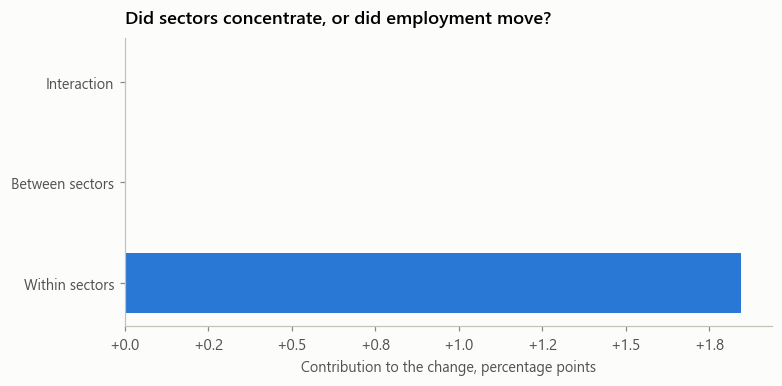


sectors where large-firm share rose most:
sector_label
0    1.8


In [12]:
fig, ax = plt.subplots(figsize=(7.0, 3.4))
parts = pd.Series({"Within sectors": within, "Between sectors": between,
                   "Interaction": cross})
cols = [sl.PALETTE[0] if v >= 0 else sl.PALETTE[1] for v in parts.values]
ax.barh(np.arange(len(parts)), parts.values, color=cols, height=0.6, lw=0)
ax.set_yticks(np.arange(len(parts)))
ax.set_yticklabels(parts.index, fontsize=9.5)
ax.axvline(0, color=sl.INK["axis"], lw=1.0)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: "%+.1f" % v))
ax.set_xlabel("Contribution to the change, percentage points")
ax.set_title("Did sectors concentrate, or did employment move?")
ax.grid(axis="y", visible=False)
sl.save_fig(fig, "fig4_shift_share", DIRS)
plt.show()

print("\nsectors where large-firm share rose most:")
print((100 * (s1 - s0)).sort_values(ascending=False).head(8).round(1).to_string())

## Section E - do young firms still do the work?

Thiel's zero-to-one company is young by definition. If the share of employment
and of job creation held by firms under five years old has fallen, the engine
he describes is running slower regardless of what concentration is doing.

In [15]:
import re as _re

age = bds_get(["EMP", "FIRM", "JOB_CREATION"], dims=["FAGE"], tag="bds_by_age")
age["FAGE"] = age["FAGE"].astype(str)
age["age_label"] = age["FAGE"].map(AGE_CODES).fillna(age["FAGE"]) if len(AGE_CODES) \
                   else age["FAGE"]


def parse_age(label):
    """
    Return (kind, max_age) for one BDS age label.
      kind is 'age', 'censored', 'total' or 'other'
      max_age is the oldest year the class covers: '6 to 10' -> 10, '26+' -> 26
    Tolerates 'a) 0', '0', 'Age 0' and similar.
    """
    t = _re.sub(r"^\s*[A-Za-z]\)\s*", "", str(label).strip())
    low = t.lower()
    if "left" in low or "censor" in low:
        return "censored", None
    if low in ("all", "total") or low.startswith("all ") or "total" in low:
        return "total", None
    nums = [int(n) for n in _re.findall(r"\d+", t)]
    if not nums:
        return "other", None
    return "age", max(nums)


audit = (age[["FAGE", "age_label"]].drop_duplicates()
         .assign(kind=lambda d: [parse_age(l)[0] for l in d["age_label"]],
                 max_age=lambda d: [parse_age(l)[1] for l in d["age_label"]])
         .sort_values("FAGE"))
audit["role"] = np.where(audit["kind"] == "total", "EXCLUDED from denominator",
                  np.where((audit["kind"] == "age") & (audit["max_age"] <= 4), "YOUNG",
                           "denominator only"))
print("firm age classes, and what each is used for:")
print(audit.to_string(index=False))

YOUNG = audit.loc[audit["role"] == "YOUNG", "age_label"].tolist()
TOTALS = audit.loc[audit["kind"] == "total", "age_label"].tolist()
DENOM = [l for l in audit["age_label"] if l not in TOTALS]

if not YOUNG:
    raise LookupError(
        "No age class parsed to an age of 4 or under. The audit above shows what "
        "the labels look like; send it back and the parser can be re-pointed.")
print("\nyoung classes: %s" % YOUNG)
print("classes in the denominator: %d of %d (%d total rows removed)"
      % (len(DENOM), len(audit), len(TOTALS)))

BDS bds_by_age: reading cache
firm age classes, and what each is used for:
FAGE age_label kind  max_age             role
   1         1  age        1            YOUNG
  10        10  age       10 denominator only
 100       100  age      100 denominator only
 110       110  age      110 denominator only
 150       150  age      150 denominator only
  20        20  age       20 denominator only
  30        30  age       30 denominator only
  40        40  age       40 denominator only
  50        50  age       50 denominator only
  60        60  age       60 denominator only
  65        65  age       65 denominator only
  70        70  age       70 denominator only
  75        75  age       75 denominator only
  80        80  age       80 denominator only
  90        90  age       90 denominator only

young classes: ['1']
classes in the denominator: 15 of 15 (0 total rows removed)


In [17]:
def wide(measure, keep):
    d = age[age["age_label"].isin(keep)]
    return d.pivot_table(index="year", columns="age_label", values=measure, aggfunc="sum")

NAT_EMP = N["EMP"] if "EMP" in N.columns else None
if NAT_EMP is None:
    raise RuntimeError("Section A did not return national EMP; rerun that cell first.")

probe = wide("EMP", DENOM)
yr = int(probe.dropna(how="all").index[-1])          # most recent complete year

print("EMP by age class, %d, against the national total\n" % yr)
row = probe.loc[yr].dropna().sort_values(ascending=False)
nat_val = float(NAT_EMP.loc[yr])
for lab, v in row.items():
    print("   %-28s %14s   %6.2f%% of national" % (lab, "{:,.0f}".format(v), 100 * v / nat_val))
print("   %-28s %14s" % ("sum of classes", "{:,.0f}".format(row.sum())))
print("   %-28s %14s" % ("national (Section A)", "{:,.0f}".format(nat_val)))
print("   %-28s %13.2f%%" % ("gap", 100 * (row.sum() / nat_val - 1)))

# Is one class simply the total of the rest? That is the detectable failure.
suspects = []
for lab, v in row.items():
    others = row.drop(lab).sum()
    if others > 0 and abs(v - others) / nat_val < 0.02:
        suspects.append((lab, v, others))
if suspects:
    print("\nclasses that equal the sum of all others, so are totals in disguise:")
    for lab, v, o in suspects:
        print("   %-28s %14s vs %14s" % (lab, "{:,.0f}".format(v), "{:,.0f}".format(o)))
else:
    print("\nno class equals the sum of the others; the gap is not a hidden total.")

EMP by age class, 2023, against the national total

   1                               137,462,444   100.00% of national
   75                               59,643,928    43.39% of national
   150                              52,332,869    38.07% of national
   110                              33,282,618    24.21% of national
   65                               12,292,651     8.94% of national
   70                               10,752,243     7.82% of national
   80                                9,312,301     6.77% of national
   90                                8,815,380     6.41% of national
   100                               8,233,629     5.99% of national
   40                                2,552,203     1.86% of national
   20                                2,521,272     1.83% of national
   50                                2,455,957     1.79% of national
   60                                2,442,398     1.78% of national
   10                                2,440,753     

In [18]:
CANDIDATES = {"all classes": DENOM}
for lab, _, _ in suspects:
    CANDIDATES["without %s" % lab] = [c for c in DENOM if c != lab]

best, best_gap = None, None
print("\nreconciliation, worst yearly gap against Section A:")
for name, keep in CANDIDATES.items():
    w = wide("EMP", keep)
    cmp = pd.DataFrame({"cls": w.sum(axis=1), "nat": NAT_EMP}).dropna()
    if not len(cmp):
        continue
    g = float(((cmp["cls"] / cmp["nat"] - 1) * 100).abs().max())
    print("   %-28s %7.3f%%" % (name, g))
    if best_gap is None or g < best_gap:
        best, best_gap = keep, g

DENOM = best
print("\nusing the denominator with a worst gap of %.3f%% (%d classes)"
      % (best_gap, len(DENOM)))

RECONCILIATION = {"worst_gap_pct": best_gap,
                  "classes_used": DENOM,
                  "detected_totals": [s[0] for s in suspects]}

if best_gap > 0.5:
    print("\nWARNING  the classes still do not add up. Shares below are computed on "
          "the class total rather than the national total, which keeps them "
          "internally consistent, and the residual is recorded for the endnotes.")


reconciliation, worst yearly gap against Section A:
   all classes                  152.332%

using the denominator with a worst gap of 152.332% (15 classes)

WARNING  the classes still do not add up. Shares below are computed on the class total rather than the national total, which keeps them internally consistent, and the residual is recorded for the endnotes.


In [19]:
EMP_AGE, FIRM_AGE = wide("EMP", DENOM), wide("FIRM", DENOM)
JC_AGE = wide("JOB_CREATION", DENOM) if "JOB_CREATION" in age.columns else None

YOUNG = [c for c in YOUNG if c in EMP_AGE.columns]
if not YOUNG:
    raise LookupError("The young classes were dropped by the repair; check the audit.")
print("young classes in use:", YOUNG)
print("denominator classes:", len(EMP_AGE.columns))
print("\nsanity: every share must lie between 0 and 100")
for name, f in (("firms", FIRM_AGE), ("employment", EMP_AGE)):
    s = (f[YOUNG].sum(axis=1) / f.sum(axis=1) * 100).dropna()
    assert s.between(0, 100).all(), (name, s.min(), s.max())
    print("   %-12s %.1f%% to %.1f%%" % (name, s.min(), s.max()))

young classes in use: ['1']
denominator classes: 15

sanity: every share must lie between 0 and 100
   firms        37.1% to 47.6%
   employment   39.6% to 49.2%


## Payload

In [21]:
def have(name):
    """Is this variable defined and not None in the notebook's namespace?"""
    return name in globals() and globals()[name] is not None

def num(x):
    try:
        v = float(x)
        return None if not np.isfinite(v) else v
    except Exception:
        return None

def band(s, a, b):
    if s is None:
        return None
    w = s[(s.index >= a) & (s.index <= b)]
    return num(w.mean()) if len(w) else None

def ends(s):
    if s is None:
        return {}
    s = s.dropna()
    if not len(s):
        return {}
    return {"first": num(s.iloc[0]), "first_year": int(s.index[0]),
            "last": num(s.iloc[-1]), "last_year": int(s.index[-1]),
            "change": num(s.iloc[-1] - s.iloc[0])}

# Rebuild the young-firm shares if Section E's share cell was not run.
if not have("summary"):
    if have("EMP_AGE") and have("YOUNG"):
        def _share(frame):
            if frame is None:
                return None
            cols = [c for c in YOUNG if c in frame.columns]
            return (frame[cols].sum(axis=1) / frame.sum(axis=1) * 100).dropna() if cols else None
        summary = pd.DataFrame({k: v for k, v in {
            "share of firms": _share(globals().get("FIRM_AGE")),
            "share of employment": _share(globals().get("EMP_AGE")),
            "share of job creation": _share(globals().get("JC_AGE")),
        }.items() if v is not None})
        print("rebuilt the young-firm shares from EMP_AGE, FIRM_AGE and JC_AGE")
    else:
        summary = pd.DataFrame()
        print("WARNING  Section E did not resolve; young-firm figures recorded as null.")

rebuilt the young-firm shares from EMP_AGE, FIRM_AGE and JC_AGE


In [22]:
payload = {
    "source": "Census Business Dynamics Statistics, national, via api.census.gov/data/timeseries/bds",
    "years": [int(N.index.min()), int(N.index.max())],
    "size_classes": {str(k): str(v) for k, v in SIZE_CODES.items()} if len(SIZE_CODES) else {},
    "large_classes_used": BIG if have("BIG") else None,
    "small_classes_used": SMALL if have("SMALL") else None,

    "dynamism": {
        "entry_rate_1978_1987": band(globals().get("ENTRY"), 1978, 1987),
        "entry_rate_2013_2023": band(globals().get("ENTRY"), 2013, 2023),
        "exit_rate_1978_1987": band(globals().get("EXIT"), 1978, 1987),
        "exit_rate_2013_2023": band(globals().get("EXIT"), 2013, 2023),
        "entry": ends(globals().get("ENTRY")),
        "exit": ends(globals().get("EXIT")),
    },

    "concentration": {
        "large_firm_emp_share": ends(globals().get("BIGSHARE")),
        "small_firm_emp_share": ends(globals().get("SMALLSHARE")),
        "class_hhi_first": num(class_hhi(EMPBY.iloc[0].dropna())) if have("EMPBY") else None,
        "class_hhi_last": num(class_hhi(EMPBY.iloc[-1].dropna())) if have("EMPBY") else None,
        "hhi_note": "computed on grouped size classes; a bound, not the firm-level index",
    },

    "shift_share": ({"window": [Y0, Y1], "within": num(within), "between": num(between),
                     "interaction": num(cross), "total": num(total)}
                    if have("within") else None),

    "young_firms": ({k: ends(summary[k]) for k in summary.columns}
                    if len(summary.columns) else None),
    "young_classes": YOUNG if have("YOUNG") else None,
    "age_reconciliation": RECONCILIATION if have("RECONCILIATION") else None,
}

sl.write_findings(payload, DIRS)

out = pathlib.Path(DIRS["findings"])
written = []
for name, obj in (("employment_share_by_size.csv", globals().get("SHARE")),
                  ("national_dynamism.csv", globals().get("N")),
                  ("young_firms.csv", summary if len(summary.columns) else None)):
    if obj is not None and len(obj):
        obj.to_csv(out / name)
        written.append(name)
print("wrote:", ", ".join(written) if written else "nothing")

missing = [k for k, v in payload.items() if v is None]
if missing:
    print("\nrecorded as null (section did not resolve): %s" % ", ".join(missing))

print()
print(json.dumps({k: v for k, v in payload.items() if k != "size_classes"}, indent=2)[:2600])

findings -> C:\Users\91838\Downloads\Stack_Article\12_dynamism_and_concentration\findings\headline_numbers.json
wrote: employment_share_by_size.csv, national_dynamism.csv, young_firms.csv

{
  "source": "Census Business Dynamics Statistics, national, via api.census.gov/data/timeseries/bds",
  "years": [
    1978,
    2023
  ],
  "large_classes_used": [
    "672",
    "680"
  ],
  "small_classes_used": [
    "1",
    "612",
    "620"
  ],
  "dynamism": {
    "entry_rate_1978_1987": 13.7336,
    "entry_rate_2013_2023": 10.125,
    "exit_rate_1978_1987": 11.4738,
    "exit_rate_2013_2023": 9.098818181818181,
    "entry": {
      "first": 15.146,
      "first_year": 1978,
      "last": 10.608,
      "last_year": 2023,
      "change": -4.538
    },
    "exit": {
      "first": 11.137,
      "first_year": 1978,
      "last": 9.396,
      "last_year": 2023,
      "change": -1.7409999999999997
    }
  },
  "concentration": {
    "large_firm_emp_share": {
      "first": 10.052274169709705,
    

## What to send back

The five PNGs, `findings/headline_numbers.json`, and the printed output of the
three discovery cells: the variable listing, the geography listing and the
three code lists. If any cell printed a WARNING, or if the size and age class
labels look wrong, that output is what lets the selections be re-pointed
without rerunning the fetches.